In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

sys.path.append(os.path.abspath("."))

from figure_style import (
    PROCESS_COLORS,
    REST_COLOR,
    apply_style,
    get_process_color,
    save_figure,
)

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
apply_style()

CONTRIB_DATA = os.path.join("contrib_data", "contrib_data.xlsx")

PROCESSES = [
    "u1_BM-pulping", "u2_leaching", "u3_Ca(OH)2_pulp", "u4_purification",
    "u5_filtrate-impurities", "u6_NaOH_pulping", "u7_precipitation_trans-Me",
    "u8_filtration_trans-Me", "u9_NaCO3-pulping", "u10_precipitation",
    "u11_filtration-Li", "u12_wastewater-storage",
]

METHOD_SHEETS = ["nr", "nr_cutoff", "gwp", "dissi_tot", "dissi_int", "dissi_ext", "eca"]


# 1. Absolute tier-1 cumulative impact (MJ-eq): nr vs nr_cutoff

Absolute score of the cumulative impact of the **tier-1 unit processes** for the
sheets `nr` (non-renewable) and `nr_cutoff` (non-renewable plus cut-off flows).
One bar per impact method: the full bar is the total score (MJ-eq) and each
stacked segment is the cumulative contribution of one unit process. The
**direct impact** of each process (column `Direct impact`) is explicitly
represented as the hatched part of its segment, e.g. `u1_BM-pulping` for
`nr_cutoff`.

In [2]:
def read_contribution_sheet(sheet):
    df = pd.read_excel(CONTRIB_DATA, sheet_name=sheet)
    tier1 = df[df["Tier"] == 1].copy()
    total_row = df[df["Tier"] == 0].iloc[0]
    return df, tier1, total_row


def text_color_for(hex_color):
    r, g, b = (int(hex_color[i:i + 2], 16) / 255 for i in (1, 3, 5))
    luminance = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return "black" if luminance > 0.55 else "white"


,method,process,cumulative_MJ-eq,direct_MJ-eq
0,nr,u1_BM-pulping,1.315699,0.000000
1,nr,u2_leaching,33.694887,0.000000
2,nr,u3_Ca(OH)2_pulp,4.218486,0.000000
3,nr,u4_purification,1.832239,0.000000
4,nr,u5_filtrate-impurities,0.951930,0.000000
5,nr,u6_NaOH_pulping,32.216452,0.000000
6,nr,u9_NaCO3-pulping,2.171124,0.000000
7,nr,TOTAL (perform_fu),76.405354,0.000000
8,nr_cutoff,u11_filtration-Li,-0.103071,-0.103071
9,nr_cutoff,u1_BM-pulping,13.592775,12.277077


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: results/absolute_tier1_nr_vs_nr_cutoff.svg, results/absolute_tier1_nr_vs_nr_cutoff.eps, results/absolute_tier1_nr_vs_nr_cutoff.csv


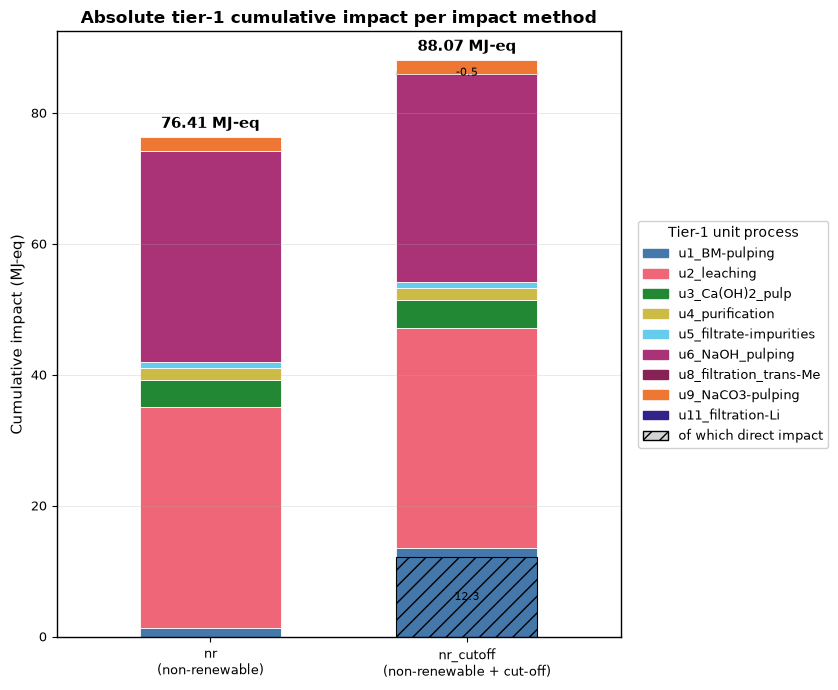

In [3]:
methods_abs = ["nr", "nr_cutoff"]

fig, ax = plt.subplots(figsize=(8.5, 7))
x = np.arange(len(methods_abs))
bar_width = 0.55

rows = []
for xi, sheet in enumerate(methods_abs):
    _, tier1, total_row = read_contribution_sheet(sheet)
    total_score = float(total_row["Cumulative impact"])
    bottom = 0.0
    pos_top = 0.0
    for _, row in tier1.iterrows():
        proc = row["Process"]
        cum = float(row["Cumulative impact"])
        direct = float(row["Direct impact"])
        color = get_process_color(proc)
        seg_bottom = bottom + min(cum, 0.0)
        ax.bar(xi, abs(cum), bottom=seg_bottom, width=bar_width,
               color=color, edgecolor="white", linewidth=0.6)
        if direct != 0:
            dir_bottom = bottom + min(direct, 0.0)
            ax.bar(xi, abs(direct), bottom=dir_bottom, width=bar_width,
                   facecolor=color, edgecolor="black", linewidth=0.8, hatch="//")
            if abs(direct) >= 0.5:
                ax.text(xi, dir_bottom + abs(direct) / 2, f"{direct:.1f}",
                        ha="center", va="center", fontsize=8, color="black")
        bottom += cum
        pos_top = max(pos_top, bottom)
        rows.append({"method": sheet, "process": proc,
                     "cumulative_MJ-eq": cum, "direct_MJ-eq": direct})
    ax.text(xi, pos_top + total_score * 0.01, f"{total_score:.2f} MJ-eq",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
    rows.append({"method": sheet, "process": "TOTAL (perform_fu)",
                 "cumulative_MJ-eq": total_score, "direct_MJ-eq": float(total_row["Direct impact"])})

plot_df = pd.DataFrame(rows)
display(plot_df)

handles = [mpatches.Patch(color=get_process_color(p), label=p) for p in PROCESSES
           if p in set(r["process"] for r in rows)]
handles.append(mpatches.Patch(facecolor="lightgrey", edgecolor="black", hatch="//",
                              label="of which direct impact"))
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5),
          title="Tier-1 unit process")
ax.set_xticks(x)
ax.set_xticklabels(["nr\n(non-renewable)", "nr_cutoff\n(non-renewable + cut-off)"])
ax.set_ylabel("Cumulative impact (MJ-eq)")
ax.set_title("Absolute tier-1 cumulative impact per impact method")
ax.set_xlim(-0.6, len(methods_abs) - 0.4)
ax.grid(axis="y")
fig.tight_layout()
save_figure(fig, "absolute_tier1_nr_vs_nr_cutoff", RESULTS_DIR, data=plot_df)
plt.show()


# 2. Relative hotspot attribution (%) of tier 1 across the seven impact methods

Same attribution plot, but in **relative terms**: every sheet of
`contrib_data.xlsx` except the `syst_*` system-level ones is one bar whose
total is 100% (`nr`, `nr_cutoff`, `gwp`, `dissi_tot`, `dissi_int`, `dissi_ext`,
`eca`); only the shares of the 12 tier-1 unit processes change between bars.
The absolute score (MJ-eq) of each method is written at the top of its bar.

For the `dissi_*` sheets (total, internal, external destruction), the bars use
the **first** `Cumulative impact (%)` column (foreground, sums to 100%) and the
attribution of both the foreground (sums to 100%) and the total with background
(does not sum to 100%, second `Cumulative impact (%)` column) is written on
each segment as `foreground% (tot total%)`. The `eca` sheet behaves the same
way: `U_i` rows hold the internal exergy destruction and a matching `U_i ext`
row (when present) holds the external one, both belonging to the same unit
process `u_i`; its score is direct, like the `dissi_*` sheets.

In [4]:
def foreground_shares(sheet):
    df = pd.read_excel(CONTRIB_DATA, sheet_name=sheet)
    if sheet == "eca":
        fg, tot = {}, {}
        for i, proc in enumerate(PROCESSES, start=1):
            base = df[df["Key"] == f"U{i}"]
            ext = df[df["Key"] == f"U{i}ext"]
            internal = float(base["I(kW)"].sum())
            external = float(ext["Total"].sum()) if len(ext) else 0.0
            fg[proc] = internal + external
            tot[proc] = float(base["Total"].sum())
        abs_score = sum(fg.values())
        fg = {p: v / abs_score * 100 for p, v in fg.items()}
        tot = {p: v / abs_score * 100 for p, v in tot.items()}
        return fg, tot, abs_score
    tier1 = df[df["Tier"] == 1]
    pct_cols = [c for c in df.columns if str(c).startswith("Cumulative impact (%)")]
    fg_col = pct_cols[0]
    tot_col = pct_cols[1] if len(pct_cols) > 1 else None
    fg, tot = {}, {}
    for _, row in tier1.iterrows():
        proc = row["Process"]
        fg[proc] = fg.get(proc, 0.0) + float(row[fg_col])
        if tot_col is not None:
            tot[proc] = tot.get(proc, 0.0) + float(row[tot_col])
    total_row = df[df["Tier"] == 0].iloc[0]
    abs_score = float(total_row["Cumulative impact"])
    fg = {p: fg.get(p, 0.0) for p in PROCESSES}
    tot = {p: tot.get(p, 0.0) for p in PROCESSES}
    return fg, tot, abs_score


shares = {}
for sheet in METHOD_SHEETS:
    fg, tot, abs_score = foreground_shares(sheet)
    shares[sheet] = {"fg": fg, "tot": tot, "abs": abs_score}
    print(f"{sheet}: total = {abs_score:.4f} MJ-eq, foreground shares sum = {sum(fg.values()):.2f}%")


nr: total = 76.4054 MJ-eq, foreground shares sum = 99.99%
nr_cutoff: total = 88.0654 MJ-eq, foreground shares sum = 99.99%
gwp: total = 4.7186 MJ-eq, foreground shares sum = 99.99%
dissi_tot: total = 23.9117 MJ-eq, foreground shares sum = 100.00%
dissi_int: total = 7.1570 MJ-eq, foreground shares sum = 99.97%
dissi_ext: total = 16.7540 MJ-eq, foreground shares sum = 100.00%


eca: total = 24.7750 MJ-eq, foreground shares sum = 100.00%


,method,process,share_foreground_pct,share_total_pct,total_score_MJ-eq
0,nr,u1_BM-pulping,1.721998,0.000000,76.405354
1,nr,u2_leaching,44.100165,0.000000,76.405354
2,nr,u3_Ca(OH)2_pulp,5.521192,0.000000,76.405354
3,nr,u4_purification,2.398050,0.000000,76.405354
4,nr,u5_filtrate-impurities,1.245894,0.000000,76.405354
5,nr,u6_NaOH_pulping,42.165176,0.000000,76.405354
6,nr,u9_NaCO3-pulping,2.841586,0.000000,76.405354
7,nr_cutoff,u1_BM-pulping,15.434867,0.000000,88.065388
8,nr_cutoff,u2_leaching,38.261214,0.000000,88.065388
9,nr_cutoff,u3_Ca(OH)2_pulp,4.790175,0.000000,88.065388


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: results/relative_tier1_hotspots_all_methods.svg, results/relative_tier1_hotspots_all_methods.eps, results/relative_tier1_hotspots_all_methods.csv


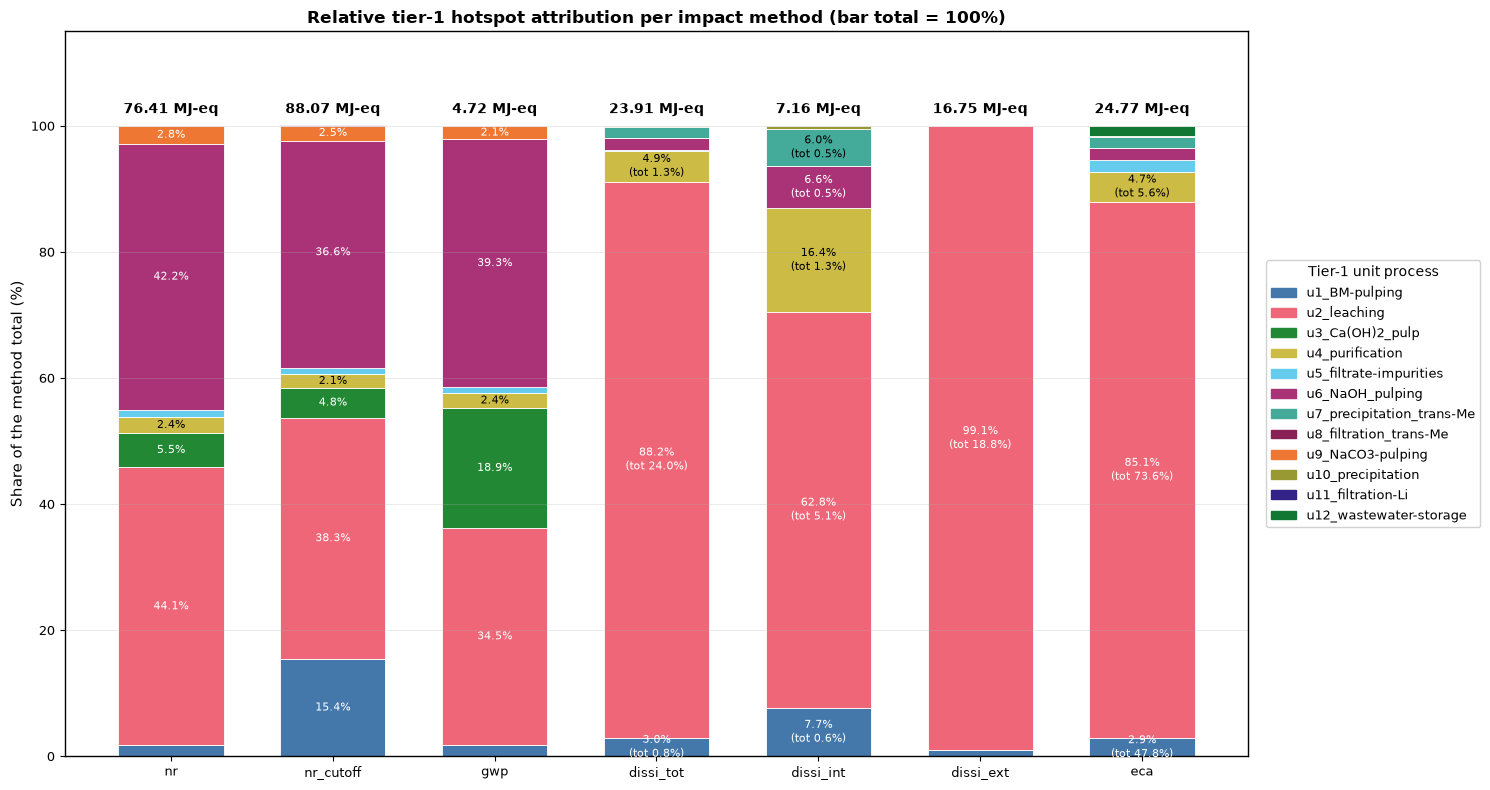

In [5]:
MIN_LABEL_PCT = 2.0

fig, ax = plt.subplots(figsize=(15, 8))
x = np.arange(len(METHOD_SHEETS))
bar_width = 0.65

rows = []
for xi, sheet in enumerate(METHOD_SHEETS):
    data = shares[sheet]
    bottom = 0.0
    for proc in PROCESSES:
        v = data["fg"][proc]
        if v == 0:
            continue
        color = get_process_color(proc)
        seg_bottom = bottom + min(v, 0.0)
        ax.bar(xi, abs(v), bottom=seg_bottom, width=bar_width,
               color=color, edgecolor="white", linewidth=0.6)
        if abs(v) >= MIN_LABEL_PCT:
            label = f"{v:.1f}%"
            if sheet.startswith("dissi") or sheet == "eca":
                label += f"\n(tot {data['tot'][proc]:.1f}%)"
            ax.text(xi, seg_bottom + abs(v) / 2, label, ha="center", va="center",
                    fontsize=8, color=text_color_for(color))
        bottom += v
        rows.append({"method": sheet, "process": proc,
                     "share_foreground_pct": data["fg"][proc],
                     "share_total_pct": data["tot"][proc],
                     "total_score_MJ-eq": data["abs"]})
    ax.text(xi, 100 + 1.5, f"{data['abs']:.2f} MJ-eq", ha="center", va="bottom",
            fontsize=10, fontweight="bold")

plot_df = pd.DataFrame(rows)
display(plot_df)

handles = [mpatches.Patch(color=get_process_color(p), label=p) for p in PROCESSES]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5),
          title="Tier-1 unit process")
ax.set_xticks(x)
ax.set_xticklabels(METHOD_SHEETS)
ax.set_ylabel("Share of the method total (%)")
ax.set_ylim(0, 115)
ax.set_title("Relative tier-1 hotspot attribution per impact method (bar total = 100%)")
ax.grid(axis="y")
fig.tight_layout()
save_figure(fig, "relative_tier1_hotspots_all_methods", RESULTS_DIR, data=plot_df)
plt.show()
